# 03 · Patient profiling and the hospital journey (1999–2008)

**Question:** which diabetic patients come back within 30 days, and what happened to them during the stay?

I use SQL (DuckDB) for the profiling, the same way I'd query a claims table, and plot the results with matplotlib.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # make src/ importable when run from notebooks/

import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt
from src.config import PROCESSED, FIGURES, SERIES, INK2, MUTED, CLASS_ORDER, style, update_results
style()

p = pd.read_parquet(PROCESSED / "patients.parquet")
con = duckdb.connect()
con.register("p", p)
BASE = p.readmit_30.mean()
print(f"{len(p):,} patients, {BASE:.1%} readmitted within 30 days")

69,987 patients, 9.0% readmitted within 30 days


## 1. Readmission rate by patient characteristic

One helper query returns, for any column: patients, % of all patients, 30-day readmission rate, and the gap to the overall rate in percentage points.

In [2]:
def rate_by(col, order=None, min_n=300):
    q = f'''
        SELECT {col} AS level, COUNT(*) AS patients,
               ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_patients,
               ROUND(100 * AVG(readmit_30), 1) AS readmit_pct
        FROM p GROUP BY 1 HAVING COUNT(*) >= {min_n}
    '''
    out = con.sql(q).df()
    out["vs_overall_pts"] = (out.readmit_pct - 100 * BASE).round(1)
    if order:
        out = out.set_index("level").reindex([o for o in order if o in set(out.level)]).reset_index()
    else:
        out = out.sort_values("readmit_pct", ascending=False)
    return out

p["prior_inpatient"] = pd.cut(p.number_inpatient, [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3+"]).astype(str)
p["prior_er"] = pd.cut(p.number_emergency, [-1, 0, 1, 100], labels=["0", "1", "2+"]).astype(str)
p["los_band"] = pd.cut(p.time_in_hospital, [0, 2, 4, 7, 14], labels=["1-2 days", "3-4 days", "5-7 days", "8-14 days"]).astype(str)
p["age_band"] = p.age_band.astype(str)
con.register("p", p)

dims = {
    "Prior hospital stays (past year)": rate_by("prior_inpatient", ["0", "1", "2", "3+"]),
    "Discharged to": rate_by("discharge_to"),
    "Primary diagnosis": rate_by("diag_1_group"),
    "Age": rate_by("age_band", ["<40", "40-49", "50-59", "60-69", "70-79", "80+"]),
    "Length of stay": rate_by("los_band", ["1-2 days", "3-4 days", "5-7 days", "8-14 days"]),
    "A1C test": rate_by("A1Cresult", ["Not tested", "Norm", ">7", ">8"]),
    "Admitting specialty": rate_by("specialty"),
}
dims["Prior hospital stays (past year)"]

,level,patients,pct_of_patients,readmit_pct,vs_overall_pts
0,0,61792,88.3,8.1,-0.9
1,1,5798,8.3,12.9,3.9
2,2,1501,2.1,18.5,9.5
3,3+,896,1.3,26.5,17.5


In [3]:
for name in ["Discharged to", "Primary diagnosis", "Admitting specialty"]:
    print("\n" + name); display(dims[name])


Discharged to


,level,patients,pct_of_patients,readmit_pct,vs_overall_pts
2,Skilled nursing / care facility,11940,17.1,15.1,6.1
4,Transferred to another hospital,1541,2.2,13.8,4.8
0,Other / unknown,3413,4.9,10.3,1.3
3,Home with home health,8364,12.0,9.5,0.5
5,Left against medical advice,409,0.6,9.5,0.5
1,Home,44320,63.3,6.9,-2.1



Primary diagnosis


,level,patients,pct_of_patients,readmit_pct,vs_overall_pts
4,Injury,4694,6.7,10.8,1.8
0,Circulatory,21389,30.6,9.7,0.7
1,Neoplasms,2538,3.6,9.1,0.1
3,Diabetes,5748,8.2,9.1,0.1
5,Genitourinary,3441,4.9,9.0,0.0
7,Other,12134,17.3,9.0,0.0
8,Musculoskeletal,4064,5.8,8.4,-0.6
2,Digestive,6488,9.3,8.0,-1.0
6,Respiratory,9491,13.6,7.3,-1.7



Admitting specialty


,level,patients,pct_of_patients,readmit_pct,vs_overall_pts
5,Psychiatry,613,0.9,11.1,2.1
10,Nephrology,797,1.1,11.0,2.0
7,Internal medicine,10641,15.2,9.8,0.8
3,Family / general practice,4978,7.1,9.7,0.7
2,Pulmonology,637,0.9,9.4,0.4
6,Unknown,33652,48.1,9.2,0.2
1,Orthopedics,2169,3.1,8.3,-0.7
4,Other specialty,2763,3.9,8.3,-0.7
8,Surgery,3685,5.3,8.0,-1.0
9,Emergency / trauma,4393,6.3,7.8,-1.2


**What stands out**

- **Prior hospital stays** are by far the strongest signal: patients with 3+ stays in the past year are readmitted at 26.5%, more than 3× the 8.1% for patients with none.
- **Discharge to a skilled nursing or care facility** (15.1%) carries more than twice the rate of discharge home (6.9%). These are sicker, frailer patients.
- **The primary diagnosis matters much less than I expected:** every group sits within 2 points of the 9.0% average. What predicts a return is the patient's history and where they go next, not why they came in.

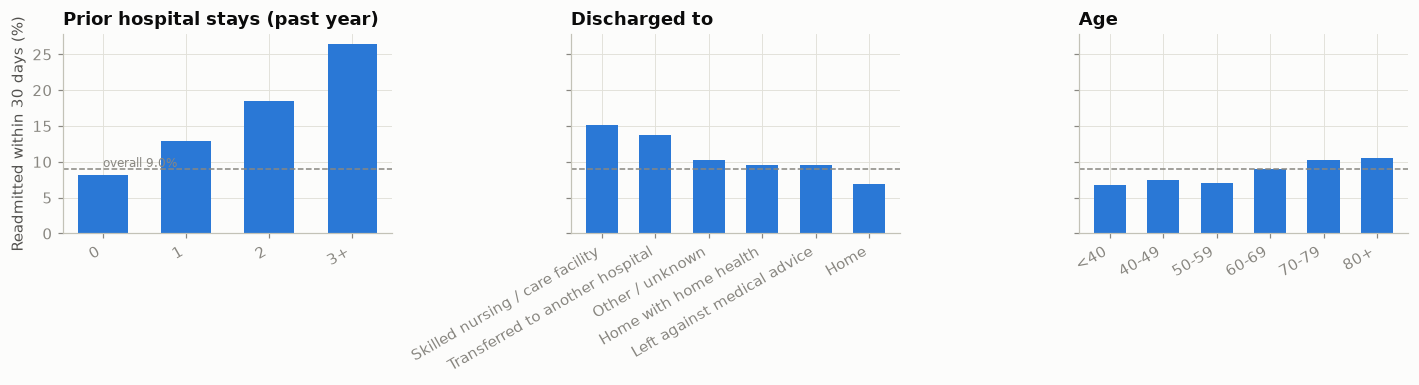

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, name in zip(axes, ["Prior hospital stays (past year)", "Discharged to", "Age"]):
    d = dims[name]
    ax.bar(d.level.astype(str), d.readmit_pct, color=SERIES[0], width=0.6)
    ax.axhline(100 * BASE, color=MUTED, lw=1, ls="--")
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=30)
    for lbl in ax.get_xticklabels(): lbl.set_ha("right")
axes[0].set_ylabel("Readmitted within 30 days (%)")
axes[0].text(0, 100 * BASE + 0.3, f"overall {100*BASE:.1f}%", color=MUTED, fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "03_readmit_by_dim.png", dpi=160); plt.show()

## 2. Profile: who gets readmitted?

The same patients, side by side: readmitted within 30 days vs. not.

In [5]:
profile = con.sql('''
    SELECT CASE WHEN readmit_30 = 1 THEN 'Readmitted <30d' ELSE 'Not readmitted' END AS grp,
           COUNT(*) AS patients,
           ROUND(AVG(age_mid), 1) AS avg_age,
           ROUND(AVG(time_in_hospital), 1) AS avg_days,
           ROUND(AVG(num_medications), 1) AS avg_medications,
           ROUND(AVG(number_diagnoses), 1) AS avg_diagnoses,
           ROUND(100 * AVG(CAST(number_inpatient > 0 AS INT)), 1) AS pct_prior_stay,
           ROUND(100 * AVG(has_heart_dx), 1) AS pct_heart_dx,
           ROUND(100 * AVG(has_kidney_dx), 1) AS pct_kidney_dx,
           ROUND(100 * AVG(CAST(insulin <> 'No' AS INT)), 1) AS pct_insulin,
           ROUND(100 * AVG(CAST(discharge_to <> 'Home' AS INT)), 1) AS pct_not_home
    FROM p GROUP BY 1 ORDER BY 1 DESC
''').df().set_index("grp").T
profile

grp,Readmitted <30d,Not readmitted
patients,6285.0,63702.0
avg_age,67.8,65.2
avg_days,4.8,4.2
avg_medications,16.6,15.6
avg_diagnoses,7.5,7.2
pct_prior_stay,20.1,10.9
pct_heart_dx,61.1,57.9
pct_kidney_dx,13.4,10.1
pct_insulin,54.8,50.7
pct_not_home,51.0,35.3


## 3. The hospital journey

For each patient I follow four steps: **was blood sugar (A1C) checked → what did it show → were diabetes medications changed → readmitted within 30 days?**

Current guidelines say a diabetic patient admitted to hospital should get an A1C test if none was done in the past 3 months, and a high result should prompt a treatment change. This shows how often that happened.

In [6]:
p["a1c_step"] = np.select([p.A1Cresult == "Not tested", p.A1Cresult == "Norm"],
                          ["Not tested", "Tested: normal"], "Tested: high (>7%)")
p["med_step"] = np.where(p["change"] == "Ch", "Meds changed", "No change")
con.register("p", p)

journey = con.sql('''
    SELECT a1c_step, med_step, COUNT(*) AS patients,
           ROUND(100 * AVG(readmit_30), 1) AS readmit_pct
    FROM p GROUP BY 1, 2 ORDER BY 1, 2
''').df()
journey["pct_of_all"] = (100 * journey.patients / len(p)).round(1)
journey

,a1c_step,med_step,patients,readmit_pct,pct_of_all
0,Not tested,Meds changed,24414,9.7,34.9
1,Not tested,No change,32727,8.7,46.8
2,Tested: high (>7%),Meds changed,5473,8.6,7.8
3,Tested: high (>7%),No change,3632,7.8,5.2
4,Tested: normal,Meds changed,1608,8.6,2.3
5,Tested: normal,No change,2133,8.6,3.0


In [7]:
tested = (p.A1Cresult != "Not tested").mean()
high = p.A1Cresult.isin([">7", ">8"])
high_changed = (p.loc[high, "change"] == "Ch").mean()
print(f"A1C checked during the stay: {tested:.1%}")
print(f"High A1C patients whose diabetes meds were changed: {high_changed:.1%}")
print(f"High A1C patients left on the same meds: {1 - high_changed:.1%}")

A1C checked during the stay: 18.4%
High A1C patients whose diabetes meds were changed: 60.1%
High A1C patients left on the same meds: 39.9%


Only **18%** of patients had their A1C checked during the stay, and **4 in 10** of those with a high result went home on unchanged diabetes medication. Patients who were tested were readmitted slightly less often than those who weren't (about 8% vs. 9%). That's a correlation, not proof testing helps, since tested patients may differ in other ways. Either way, the bigger gap is **whether anyone looked**, not which drug was chosen.

## 4. What these patients were treated with (1999–2008)

Share of patients on each drug class during the stay, using the classes from the NLM RxClass API (notebook 02).

In [8]:
from src.classes import classes_of     # the same classifier notebook 02 uses for CMS drug names
DRUG_COLS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide", "glipizide",
             "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol", "troglitazone",
             "tolazamide", "insulin", "glyburide-metformin", "glipizide-metformin", "glimepiride-pioglitazone",
             "metformin-rosiglitazone", "metformin-pioglitazone"]
col_classes = classes_of

classes = sorted({c for col in DRUG_COLS for c in col_classes(col)}, key=CLASS_ORDER.index)
for c in classes:
    cols = [col for col in DRUG_COLS if c in col_classes(col)]
    p["on_" + c] = (p[cols] != "No").any(axis=1).astype(int)

then = pd.DataFrame({c: [100 * p["on_" + c].mean()] for c in classes}, index=["% of patients"]).T.round(1)
then["% of heart-disease patients"] = [round(100 * p.loc[p.has_heart_dx == 1, "on_" + c].mean(), 1) for c in classes]
then

,% of patients,% of heart-disease patients
Biguanide (metformin),21.9,20.6
Sulfonylurea,29.7,32.3
Thiazolidinedione,14.1,14.7
Meglitinide,2.0,2.2
Alpha-glucosidase inhibitor,0.3,0.3
Insulin,51.0,48.8


In [9]:
heart = p.has_heart_dx.mean()
print(f"Patients with a heart / circulatory diagnosis: {heart:.1%}, readmitted {p.loc[p.has_heart_dx==1,'readmit_30'].mean():.1%}")
print(f"Patients with a kidney diagnosis: {p.has_kidney_dx.mean():.1%}, readmitted {p.loc[p.has_kidney_dx==1,'readmit_30'].mean():.1%}")

Patients with a heart / circulatory diagnosis: 58.2%, readmitted 9.4%
Patients with a kidney diagnosis: 10.4%, readmitted 11.6%


In 1999–2008, **none** of these patients were on a GLP-1 or SGLT2 drug, the two classes guidelines now recommend for diabetic patients with heart or kidney disease (the first GLP-1, exenatide, arrived in 2005 and the first SGLT2 in 2013). Treatment was insulin, sulfonylureas and metformin. Yet **58%** of patients had a heart or circulatory diagnosis and **10%** a kidney diagnosis (readmitted at 11.6%). Those patients are the ones whose recommended treatment has changed most since. Notebook 05 looks at those drugs today, and notebook 06 asks for which patients they pay for themselves.

In [10]:
p.to_parquet(PROCESSED / "patients_profiled.parquet", index=False)
update_results("profile", {
    "overall_readmit": round(100 * BASE, 1),
    "by": {k: v[["level", "patients", "pct_of_patients", "readmit_pct"]].astype({"level": str}).to_dict("records")
           for k, v in dims.items()},
    "profile": profile.reset_index().rename(columns={"index": "metric"}).to_dict("records"),
    "journey": journey.to_dict("records"),
    "a1c_tested_pct": round(100 * tested, 1),
    "high_a1c_changed_pct": round(100 * high_changed, 1),
    "heart_dx_pct": round(100 * heart, 1),
    "heart_dx_readmit": round(100 * p.loc[p.has_heart_dx == 1, "readmit_30"].mean(), 1),
    "kidney_dx_pct": round(100 * p.has_kidney_dx.mean(), 1),
    "classes_then": then.reset_index().rename(columns={"index": "drug_class"}).to_dict("records"),
})
print("saved")

saved
